# Notebook 33 — Chronological out-of-fold Random Forest stacking

**Research only.** Compare the full-history Random Forest to cross-fitted probability stacking. The historical 20% final holdout and prospective prediction ledger remain untouched. Every OOF prediction comes from a model trained on strictly earlier completed labels. The outer validation is later than all model training and meta-model fitting.

**Important limitation:** OOF meta models learn from earlier base-model fits while validation probabilities come from a refit on the full outer training window; distribution shift is possible. Evaluate the full-history baseline on the same outer folds.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
if not (ROOT/'src').exists():raise FileNotFoundError('Open inside stock_ml_dynamic repository')
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from stock_ml_dynamic.pooled_models import load_master
from stock_ml_dynamic.oof_stacking_research import run_research
SEED=42
N_OUTER=3
OOF_WINDOWS=5
CAP=60000
TREES=200
LEAF=20
CLIP=(.005,.995)
THRESHOLD=.45
COST_BPS=10
OUTPUT=ROOT/'artifacts'/'notebook33_oof_stacking'
print('Root:',ROOT)

Root: /home/oem/Documents/github/stock_ml_dynamic


## 1. Load the persisted master table

In [2]:
master,latest,bundle,manifest=load_master(ROOT/'artifacts/master_tables/1d')
print('Master:',master.shape,'Latest:',latest.shape)
print('Date range:',master.bar_timestamp.min(),master.bar_timestamp.max())
print('Tickers:',master.symbol.nunique())

Master: (431299, 27) Latest: (220, 27)
Date range: 2018-11-28 00:00:00+00:00 2026-11-11 00:00:00+00:00
Tickers: 220


## 2. Run chronological OOF research

This may take time on the workstation. Four methods × three outer folds; five inner OOF base fits per outer fold. No random row shuffling.

In [3]:
result=run_research(master,n_outer=N_OUTER,windows=OOF_WINDOWS,cap=CAP,trees=TREES,leaf=LEAF,
                    seed=SEED,clip=CLIP,threshold=THRESHOLD,cost_bps=COST_BPS,output_dir=OUTPUT)
outer=result['outer'];audit=result['audit']
print('Development cutoff:',result['cutoff'],'Feature count:',result['feature_count'])
display(outer)

Development cutoff: 2025-04-09 00:00:00+00:00 Feature count: 87


,fold,model,n,accuracy,majority_baseline,auc,logloss,brier_up,coverage,entry_count,up_precision,mean_net,median_net,oof_rows,outer_train_rows,outer_valid_rows,feature_count
0,1,full_history_rf,51646,0.417438,0.416799,0.560741,1.073254,0.245177,0.354606,18314,0.442885,-0.000419,-0.000334,109260,180395,51646,87
1,1,oof_meta_logistic,51646,0.418232,0.416799,0.564248,1.068059,0.242916,0.387678,20022,0.444361,-0.000428,-0.000452,109260,180395,51646,87
2,1,oof_meta_rf,51646,0.417554,0.416799,0.562135,1.068497,0.243254,0.334895,17296,0.436748,-0.000716,-0.001000,109260,180395,51646,87
3,1,oof_augmented_rf,51646,0.414011,0.416799,0.553295,1.078734,0.246560,0.387368,20006,0.442267,-0.000520,-0.000347,109260,180395,51646,87
4,2,full_history_rf,51863,0.427839,0.414920,0.560675,1.064918,0.242205,0.179627,9316,0.451159,0.000726,0.000580,140867,232258,51863,87
5,2,oof_meta_logistic,51863,0.428803,0.414920,0.562896,1.065078,0.241845,0.082718,4290,0.468998,0.001695,0.000648,140867,232258,51863,87
6,2,oof_meta_rf,51863,0.429690,0.414920,0.562649,1.065448,0.241864,0.060621,3144,0.472328,0.001376,0.000719,140867,232258,51863,87
7,2,oof_augmented_rf,51863,0.424464,0.414920,0.560405,1.065348,0.242574,0.203903,10575,0.455603,0.000921,0.000715,140867,232258,51863,87
8,3,full_history_rf,52325,0.430540,0.426546,0.573016,1.060679,0.244138,0.247759,12964,0.460429,0.000650,0.000562,172583,284338,52325,87
9,3,oof_meta_logistic,52325,0.430387,0.426546,0.572563,1.061463,0.244295,0.124281,6503,0.478087,0.001572,0.000991,172583,284338,52325,87


## 3. Audit strictly chronological training and prediction windows

In [4]:
display(audit)
assert (pd.to_datetime(audit.latest_train_outcome,utc=True)<pd.to_datetime(audit.earliest_pred_bar,utc=True)).all()
print('PASS: all OOF training labels predate prediction bars')

,outer_fold,window,fit_rows,pred_rows,latest_train_outcome,earliest_pred_bar
0,1,1,70924,21522,2020-05-18 00:00:00+00:00,2020-05-19 00:00:00+00:00
1,1,2,92446,21666,2020-10-12 00:00:00+00:00,2020-10-13 00:00:00+00:00
2,1,3,114109,21949,2021-03-10 00:00:00+00:00,2021-03-11 00:00:00+00:00
3,1,4,136056,22032,2021-08-04 00:00:00+00:00,2021-08-05 00:00:00+00:00
4,1,5,158088,22091,2021-12-29 00:00:00+00:00,2021-12-30 00:00:00+00:00
5,2,1,91180,27640,2020-10-02 00:00:00+00:00,2020-10-05 00:00:00+00:00
6,2,2,118817,28257,2021-04-12 00:00:00+00:00,2021-04-13 00:00:00+00:00
7,2,3,147072,28116,2021-10-15 00:00:00+00:00,2021-10-18 00:00:00+00:00
8,2,4,175187,28427,2022-04-22 00:00:00+00:00,2022-04-25 00:00:00+00:00
9,2,5,203614,28427,2022-10-28 00:00:00+00:00,2022-10-31 00:00:00+00:00


PASS: all OOF training labels predate prediction bars


## 4. Compare model performance

accuracy          majority_baseline               auc  \
                      mean      std              mean      std     mean   
model                                                                     
full_history_rf    0.42527  0.00692           0.41942  0.00624  0.56481   
oof_augmented_rf   0.42176  0.00682           0.41942  0.00624  0.56095   
oof_meta_logistic  0.42581  0.00661           0.41942  0.00624  0.56657   
oof_meta_rf        0.42643  0.00778           0.41942  0.00624  0.56583   

                            logloss          brier_up          coverage  \
                       std     mean      std     mean      std     mean   
model                                                                     
full_history_rf    0.00711  1.06628  0.00640  0.24384  0.00151  0.26066   
oof_augmented_rf   0.00794  1.06877  0.00877  0.24459  0.00199  0.27623   
oof_meta_logistic  0.00523  1.06487  0.00330  0.24302  0.00123  0.19823   
oof_meta_rf        0.00596  1.06496  0.00380  0.24308  0.00114  0.15779   

                           up_precision          mean_net           \
                       std         mean      std     mean      std   
model                                                                
full_history_rf    0.08820      0.45149  0.00878  0.00032  0.00064   
oof_augmented_rf   0.09770      0.44909  0.00667  0.00020  0.00072   
oof_meta_logistic  0.16538      0.46382  0.01745  0.00095  0.00119   
oof_meta_rf        0.15362      0.46650  0.02731  0.00095  0.00149   

                   entry_count              
                          mean         std  
model                                       
full_history_rf    13531.33333  4525.74870  
oof_augmented_rf   14334.66667  4997.67869  
oof_meta_logistic  10271.66667  8516.22524  
oof_meta_rf         8171.33333  7915.86264

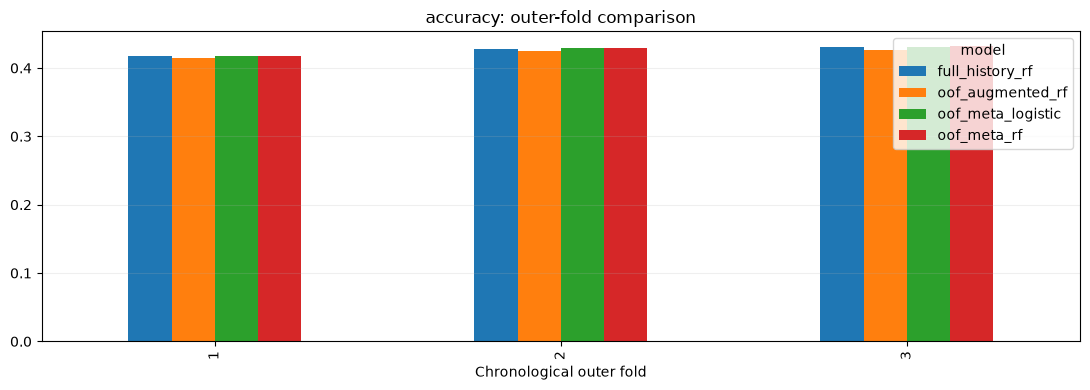

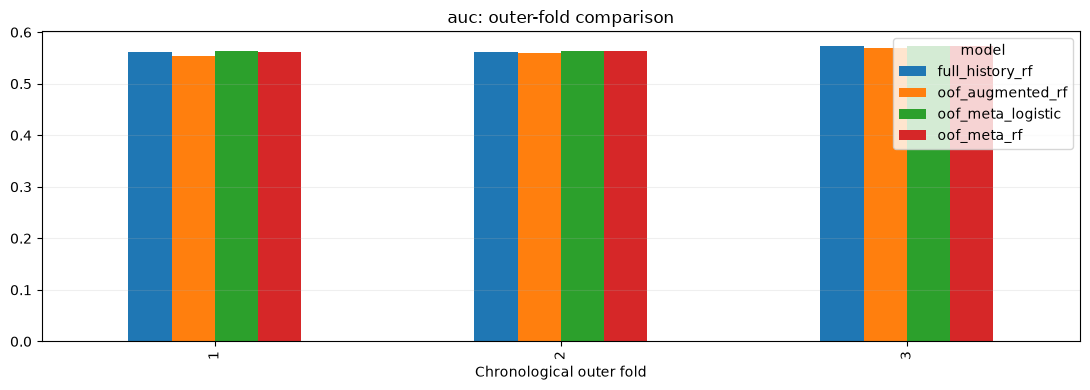

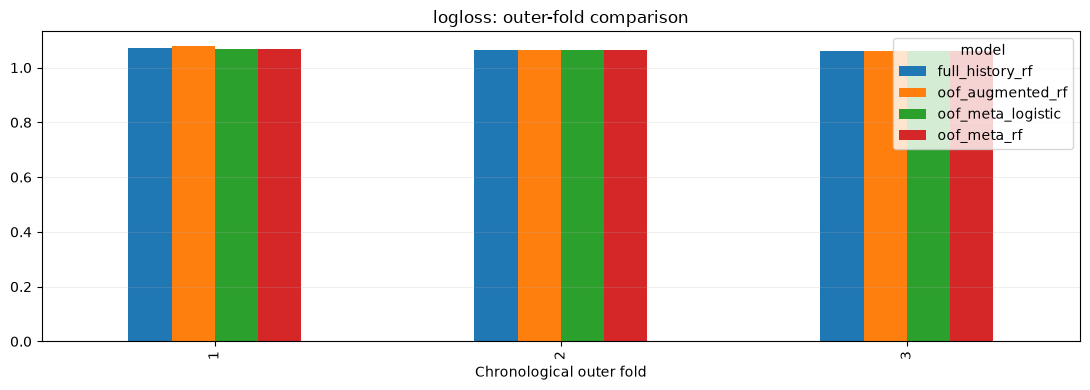

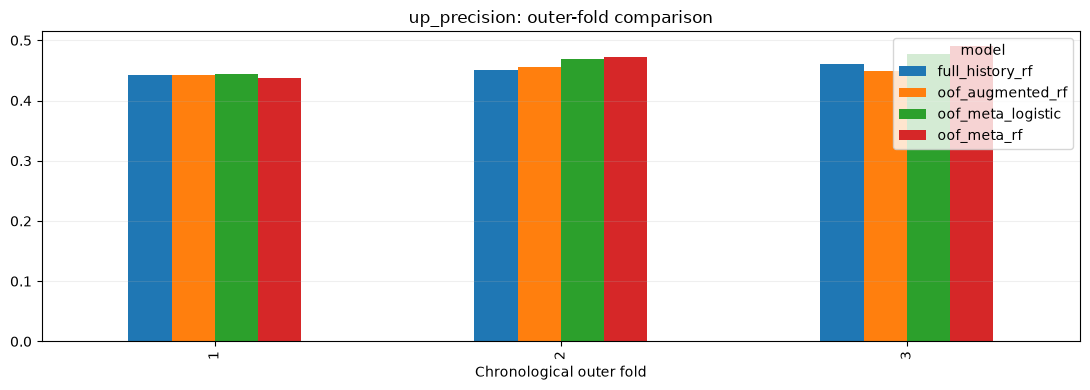

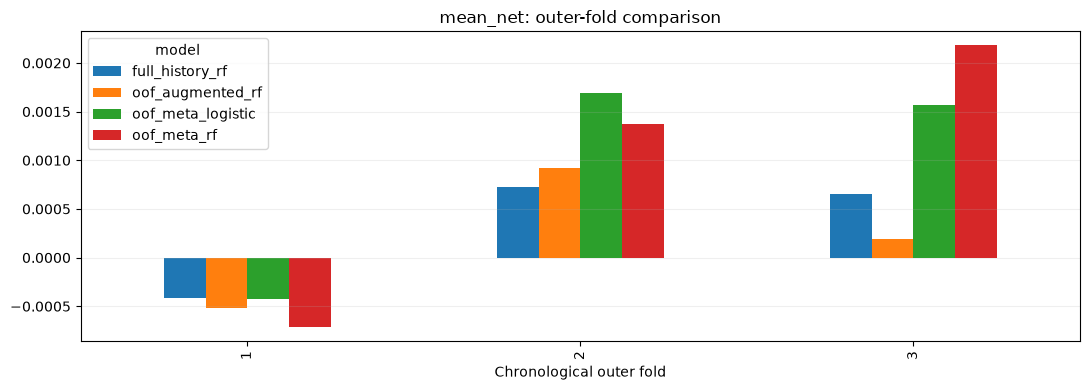

In [5]:
metrics=['accuracy','majority_baseline','auc','logloss','brier_up','coverage','up_precision','mean_net','entry_count']
summary=outer.groupby('model')[metrics].agg(['mean','std']).round(5)
display(summary)
for metric in ['accuracy','auc','logloss','up_precision','mean_net']:
    ax=outer.pivot(index='fold',columns='model',values=metric).plot(kind='bar',figsize=(11,4),title=f'{metric}: outer-fold comparison')
    ax.set_xlabel('Chronological outer fold');ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

## 5. Paired differences against full-history Random Forest

In [6]:
base=outer.loc[outer.model.eq('full_history_rf')].set_index('fold')
paired=[]
for name,g in outer.groupby('model'):
    if name=='full_history_rf':continue
    g=g.set_index('fold')
    for metric in ['accuracy','auc','logloss','up_precision','mean_net','coverage']:
        diff=(g[metric]-base[metric]).dropna()
        paired.append({'model':name,'metric':metric,'mean_difference':diff.mean(),'min_difference':diff.min(),
                       'max_difference':diff.max(),'positive_folds':int((diff>0).sum()),'folds':len(diff)})
display(pd.DataFrame(paired).round(5))

,model,metric,mean_difference,min_difference,max_difference,positive_folds,folds
0,oof_augmented_rf,accuracy,-0.00351,-0.00373,-0.00337,0,3
1,oof_augmented_rf,auc,-0.00386,-0.00745,-0.00027,0,3
2,oof_augmented_rf,logloss,0.00249,0.00043,0.00548,3,3
3,oof_augmented_rf,up_precision,-0.00240,-0.01102,0.00444,1,3
4,oof_augmented_rf,mean_net,-0.00012,-0.00046,0.00020,1,3
5,oof_augmented_rf,coverage,0.01557,-0.01034,0.03276,2,3
6,oof_meta_logistic,accuracy,0.00054,-0.00015,0.00096,2,3
7,oof_meta_logistic,auc,0.00176,-0.00045,0.00351,2,3
8,oof_meta_logistic,logloss,-0.00142,-0.00519,0.00078,2,3
9,oof_meta_logistic,up_precision,0.01232,0.00148,0.01784,3,3


## 6. Interpretation and decision rules

A stacking method is promising only if it improves outer-fold discrimination or calibration consistently, retains practical entry coverage, and does not concentrate apparent gains into a few trades. A positive mean return alone is insufficient; these diagnostics do not model slippage, portfolio constraints, or correlated trades. Do not promote a model from these development-fold results alone.

In [7]:
print('Saved outputs to:',OUTPUT)
print('Best mean accuracy:',outer.groupby('model').accuracy.mean().sort_values(ascending=False).head())
print('No historical final-holdout evaluation performed.')

Saved outputs to: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook33_oof_stacking
Best mean accuracy: model
oof_meta_rf          0.426431
oof_meta_logistic    0.425807
full_history_rf      0.425272
oof_augmented_rf     0.421763
Name: accuracy, dtype: float64
No historical final-holdout evaluation performed.
